# Objetivo 2 — Descobrir grupos de fotos**Entrada:** `clip_embeddings.npz` (294 × 512) e `image_features.csv`**Saídas:** `data/processed/Airbnb/image_clusters.csv`, figuras em `outputs/`A pergunta: existem **tipos recorrentes de foto de capa** no Airbnb paulistano, eeles se associam a tipo de imóvel, preço ou bairro?Agrupar os embeddings do CLIP é agrupar as fotos por semelhança visual — semrótulo, sem supervisão. Dois cuidados que a análise exige:1. **Desduplicar.** 7 dos 294 anúncios reaproveitam foto de outro anúncio (um par   com cosseno 1,000 — mesmo host, três quartos na mesma casa). Formariam grupo   artificial.2. **Nomear olhando as fotos.** O número do cluster não significa nada; o grupo só   vira resultado quando a gente abre as imagens e vê o que elas têm em comum.

## 1. Carregar

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

IMG_DIR = Path("../data/raw/Airbnb/photos")
PROC    = Path("../data/processed/Airbnb")
OUT     = Path("../outputs")
OUT.mkdir(exist_ok=True)

z    = np.load(PROC / "clip_embeddings.npz")
E, ids = z["emb"], z["ids"]
img  = pd.read_csv(PROC / "image_features.csv")
lst  = pd.read_csv("../data/processed/listings_aggregated.csv", low_memory=False,
                   usecols=["id", "room_type", "distrito", "price_num", "accommodates",
                            "review_scores_rating", "host_id"])
df = img.merge(lst, on="id", how="left")

assert (df.id.to_numpy() == ids).all(), "ordem do CSV e do npz divergem"
print("embeddings:", E.shape, "| tabela:", df.shape)

embeddings: (294, 512) | tabela: (294, 35)


## 2. DesduplicarPares com cosseno > 0,97 são a mesma foto (ou quase). Mantém-se um de cada grupo.

In [2]:
S = E @ E.T
np.fill_diagonal(S, -1)

dup = set()
for a, b in zip(*np.where(np.triu(S, 1) > 0.97)):
    if a not in dup:
        dup.add(int(b))          # mantém o primeiro, descarta o repetido

keep = np.array([i for i in range(len(ids)) if i not in dup])
Ek, dfk = E[keep], df.iloc[keep].reset_index(drop=True)

print(f"descartados por duplicidade: {len(dup)}")
print(f"restam: {len(dfk)} anúncios")

descartados por duplicidade: 4
restam: 290 anúncios


## 3. Redução de dimensão512 dimensões para 287 observações é mais variável que amostra — k-means nesseregime encontra estrutura que não existe. PCA primeiro, mantendo o número decomponentes que cobre 90 % da variância.

In [3]:
from sklearn.decomposition import PCA

p_full = PCA().fit(Ek)
cum    = np.cumsum(p_full.explained_variance_ratio_)
n_comp = int(np.searchsorted(cum, 0.90) + 1)

X = PCA(n_components=n_comp, random_state=0).fit_transform(Ek)
print(f"componentes para 90% da variância: {n_comp}")
print(f"PC1 sozinho: {100 * p_full.explained_variance_ratio_[0]:.1f}%")
print("X:", X.shape)

componentes para 90% da variância: 81
PC1 sozinho: 11.6%
X: (290, 81)


## 4. Escolher *k*Silhouette médio para cada *k*. Com ~290 observações, espere algo entre 3 e 7grupos nítidos — pedir 20 produz subdivisões instáveis.

2     0.1670
3     0.0997
4     0.0547
5     0.0509
6     0.0543
7     0.0500
8     0.0546
9     0.0524
10    0.0534

k escolhido: 2  (silhouette 0.167)


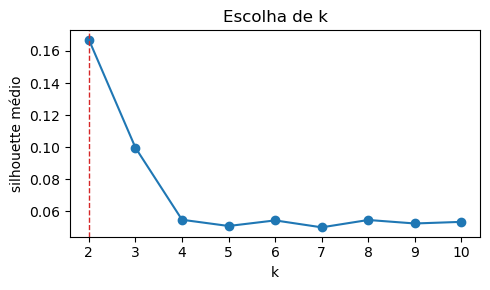

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

scores = {}
for k in range(2, 11):
    lab = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(X)
    scores[k] = silhouette_score(X, lab)

s = pd.Series(scores, name="silhouette")
print(s.round(4).to_string())

K = int(s.idxmax())
print(f"\nk escolhido: {K}  (silhouette {s.max():.3f})")

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(s.index, s.values, "o-")
ax.axvline(K, color="tab:red", ls="--", lw=1)
ax.set_xlabel("k"); ax.set_ylabel("silhouette médio"); ax.set_title("Escolha de k")
plt.tight_layout(); plt.savefig(OUT / "clusters_silhouette.png", dpi=110); plt.show()

In [5]:
km  = KMeans(n_clusters=K, n_init=50, random_state=0).fit(X)
dfk["cluster"] = km.labels_

print(dfk.cluster.value_counts().sort_index().to_string())

cluster
0     70
1    220


### EstabilidadeCluster achado em n≈290 pode ser artefato da amostra. Reamostragem bootstrap:quantas vezes dois anúncios do mesmo cluster continuam juntos ao reajustar.

In [6]:
rng = np.random.default_rng(0)
co  = np.zeros((len(X), len(X)))
cnt = np.zeros((len(X), len(X)))

for _ in range(30):
    idx = rng.choice(len(X), size=len(X), replace=True)
    uniq = np.unique(idx)
    lab  = KMeans(n_clusters=K, n_init=10, random_state=None).fit_predict(X[uniq])
    same = (lab[:, None] == lab[None, :]).astype(float)
    co[np.ix_(uniq, uniq)]  += same
    cnt[np.ix_(uniq, uniq)] += 1

stab = np.divide(co, cnt, out=np.zeros_like(co), where=cnt > 0)
orig = (km.labels_[:, None] == km.labels_[None, :])
print(f"co-ocorrência média dentro do mesmo cluster : {stab[orig].mean():.2f}")
print(f"co-ocorrência média entre clusters distintos: {stab[~orig].mean():.2f}")
print("\n(quanto mais separados, mais estável a partição)")

co-ocorrência média dentro do mesmo cluster : 0.91
co-ocorrência média entre clusters distintos: 0.17

(quanto mais separados, mais estável a partição)


## 5. Visualizar

/opt/anaconda3/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


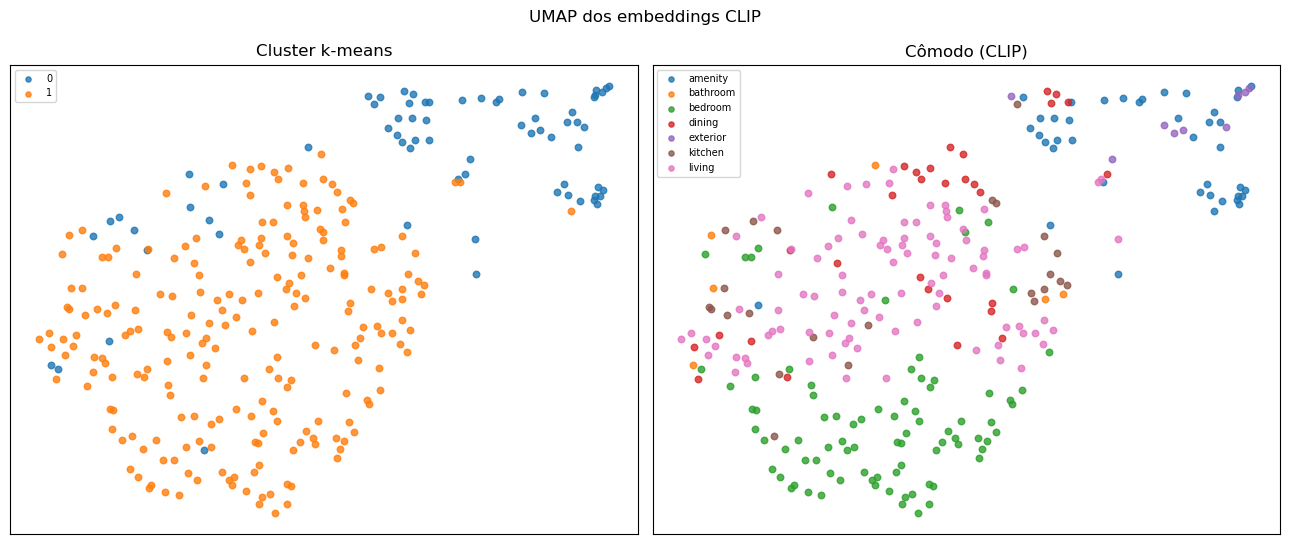

In [7]:
import umap

emb2 = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=0).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (col, title) in zip(axes, [("cluster", "Cluster k-means"), ("room_pred", "Cômodo (CLIP)")]):
    for v, g in dfk.groupby(col):
        m = dfk[col] == v
        ax.scatter(emb2[m.to_numpy(), 0], emb2[m.to_numpy(), 1], s=22, alpha=.8, label=str(v))
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(fontsize=7, markerscale=.8)
plt.suptitle("UMAP dos embeddings CLIP")
plt.tight_layout(); plt.savefig(OUT / "clusters_umap.png", dpi=110, bbox_inches="tight"); plt.show()

## 6. Caracterizar os gruposAntes de nomear, ver no que eles diferem de fato.

In [8]:
print("=== composição por cômodo previsto (%) ===")
print((pd.crosstab(dfk.cluster, dfk.room_pred, normalize="index") * 100).round(0).to_string())
print("\n=== tipo de anúncio (%) ===")
print((pd.crosstab(dfk.cluster, dfk.room_type, normalize="index") * 100).round(0).to_string())

=== composição por cômodo previsto (%) ===
room_pred  amenity  bathroom  bedroom  dining  exterior  kitchen  living
cluster                                                                 
0             54.0       1.0      4.0    13.0      13.0      4.0    10.0
1              1.0       2.0     37.0    10.0       0.0     10.0    40.0

=== tipo de anúncio (%) ===
room_type  Entire home/apt  Hotel room  Private room  Shared room
cluster                                                          
0                     74.0         0.0          24.0          1.0
1                     67.0         0.0          32.0          1.0


In [9]:
cols = ["img_brightness", "img_contrast", "img_colorfulness", "img_sharpness",
        "img_cleanliness", "img_space", "img_light", "img_decor", "img_view", "img_leisure",
        "price_num", "accommodates", "review_scores_rating"]
perfil = dfk.groupby("cluster")[cols].median().round(3)
print("=== mediana por cluster ===")
print(perfil.to_string())

=== mediana por cluster ===
         img_brightness  img_contrast  img_colorfulness  img_sharpness  img_cleanliness  img_space  img_light  img_decor  img_view  img_leisure  price_num  accommodates  review_scores_rating
cluster                                                                                                                                                                                       
0                 0.469         0.241            41.171        871.803            0.006      0.027      0.038      0.021    -0.013        0.001     340.39           2.0                  4.86
1                 0.566         0.227            34.810        564.904            0.017      0.026      0.038      0.027    -0.020       -0.008     291.00           2.0                  4.86


### As fotos de cada grupo**Esta é a célula que transforma número em resultado.** Para cada cluster, as 6fotos mais próximas do centróide — isto é, as mais representativas do grupo.O nome do cluster sai daqui, não da tabela acima.

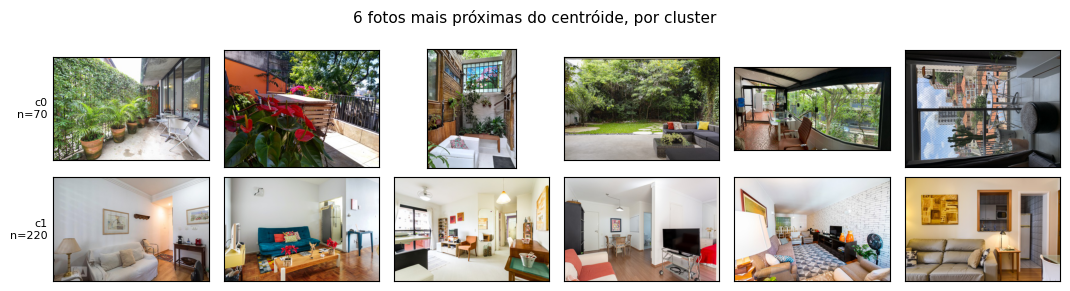

In [10]:
N = 6
fig, axes = plt.subplots(K, N, figsize=(N * 1.8, K * 1.5))
axes = np.atleast_2d(axes)

for c in range(K):
    m    = np.where(dfk.cluster.to_numpy() == c)[0]
    d    = np.linalg.norm(X[m] - km.cluster_centers_[c], axis=1)
    sel  = m[np.argsort(d)[:N]]
    for j in range(N):
        ax = axes[c, j]
        ax.set_xticks([]); ax.set_yticks([])
        if j < len(sel):
            ax.imshow(Image.open(IMG_DIR / f"{int(dfk.id.iloc[sel[j]])}.jpg"))
        if j == 0:
            ax.set_ylabel(f"c{c}\nn={len(m)}", fontsize=8, rotation=0, ha="right", va="center")

plt.suptitle("6 fotos mais próximas do centróide, por cluster", fontsize=11)
plt.tight_layout(); plt.savefig(OUT / "clusters_examples.png", dpi=110, bbox_inches="tight"); plt.show()

## 7. Os grupos dizem algo sobre preço ou bairro?

In [11]:
from scipy import stats

g = [dfk.price_num[dfk.cluster == c].dropna() for c in range(K)]
H, p = stats.kruskal(*g)
print(f"preço entre clusters  — Kruskal-Wallis H={H:.1f}, p={p:.4f}")

g2 = [dfk.review_scores_rating[dfk.cluster == c].dropna() for c in range(K)]
H2, p2 = stats.kruskal(*g2)
print(f"nota  entre clusters  — Kruskal-Wallis H={H2:.1f}, p={p2:.4f}")

print("\n=== preço mediano por cluster ===")
print(dfk.groupby("cluster").price_num.agg(["median", "count"]).round(0).to_string())

preço entre clusters  — Kruskal-Wallis H=1.4, p=0.2451
nota  entre clusters  — Kruskal-Wallis H=0.5, p=0.4597

=== preço mediano por cluster ===
         median  count
cluster               
0         340.0     70
1         291.0    219


## 8. Gravar

In [12]:
out = dfk[["id", "cluster", "room_pred", "room_conf"]].copy()
out.to_csv(PROC / "image_clusters.csv", index=False)
print(f"{PROC / 'image_clusters.csv'} -> {out.shape}")
print(f"\ndescartados por duplicidade e ausentes do arquivo: {len(df) - len(dfk)}")

../data/processed/Airbnb/image_clusters.csv -> (290, 4)

descartados por duplicidade e ausentes do arquivo: 4
